# Customer Behaviour: Exploratory Data Analysis

**Data:** cleaned Online Retail II tables (`sales` and `returns`) from `01_data_cleaning.ipynb` (run that notebook first).
**Goal:** understand how customers buy, so we can define churn and choose the snapshot dates.

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# One clean style for all charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# Folder where the charts are saved (they are used in the README)
fig_dir = Path("../reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

## Load the cleaned data and build an invoice-level table

In [2]:
sales = pd.read_parquet("../data/processed/sales.parquet")
returns = pd.read_parquet("../data/processed/returns.parquet")

# Revenue of each row = quantity x price
sales["line_total"] = sales["quantity"] * sales["price"]

# One row per invoice. A "purchase" is one invoice (one shopping trip), not one product line.
invoices = (
    sales.groupby(["customer_id", "invoice"])
    .agg(invoice_date=("invoicedate", "min"), revenue=("line_total", "sum"))
    .reset_index()
)

print("Sales:", sales.shape, "| Returns:", returns.shape)
print("Invoices:", len(invoices), "| Customers:", invoices["customer_id"].nunique())

Sales: (775278, 10) | Returns: (16285, 9)
Invoices: 36480 | Customers: 5851


## When do customers buy? Monthly activity

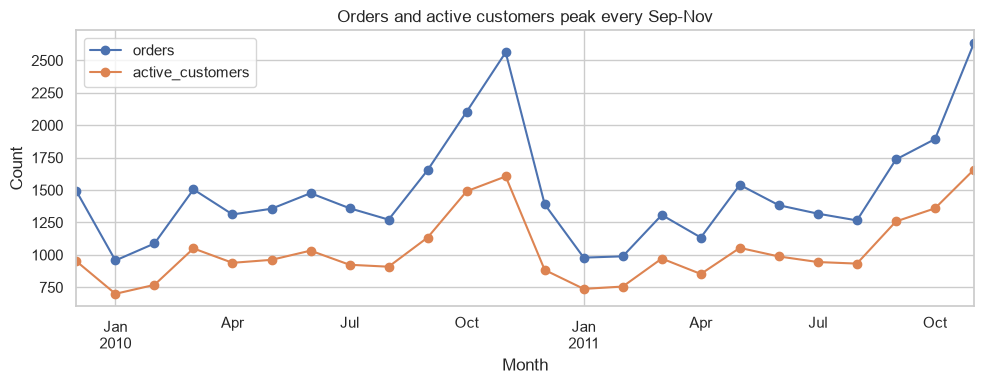

In [3]:
# Orders and active customers per month
monthly = invoices.groupby(invoices["invoice_date"].dt.to_period("M")).agg(
    orders=("invoice", "nunique"),
    active_customers=("customer_id", "nunique"),
)

# Drop the last month: the data ends on 9 Dec 2011, so Dec 2011 is incomplete
monthly = monthly.iloc[:-1]
monthly.index = monthly.index.to_timestamp()

monthly.plot(marker="o", title="Orders and active customers peak every Sep-Nov")
plt.xlabel("Month")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(fig_dir / "monthly_activity.png", dpi=150, bbox_inches="tight")
plt.show()

## How long do customers wait between purchases?

count    30629.0
mean        51.8
std         75.9
min          0.0
50%         25.0
75%         62.0
90%        136.0
95%        207.0
max        714.0
Name: days_since_prev, dtype: float64


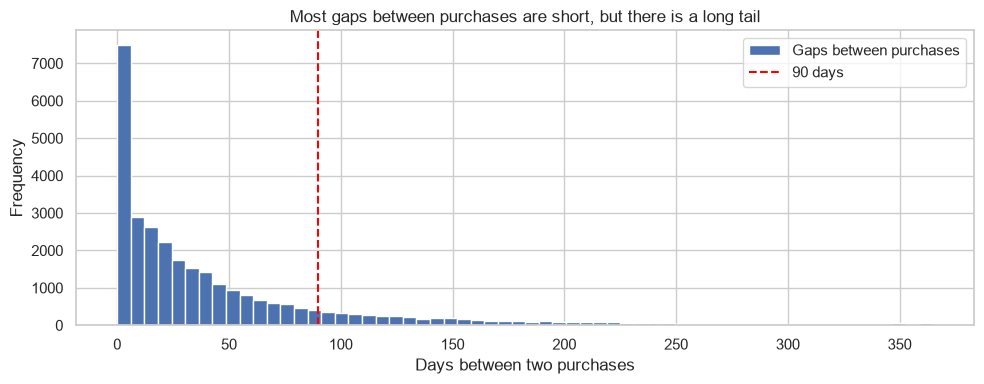

In [4]:
# Days between two consecutive purchases of the same customer
invoices = invoices.sort_values(["customer_id", "invoice_date"])
invoices["days_since_prev"] = invoices.groupby("customer_id")["invoice_date"].diff().dt.days
gaps = invoices["days_since_prev"].dropna()

# Typical gaps: median, 75%, 90% and 95% of the gaps
print(gaps.describe(percentiles=[0.5, 0.75, 0.9, 0.95]).round(1))

# Histogram of the gaps, shown up to one year
gaps[gaps <= 365].plot.hist(bins=60, label="Gaps between purchases", title="Most gaps between purchases are short, but there is a long tail")
plt.axvline(90, color="red", linestyle="--", label="90 days")
plt.xlabel("Days between two purchases")
plt.legend()
plt.tight_layout()
plt.savefig(fig_dir / "purchase_gaps.png", dpi=150, bbox_inches="tight")
plt.show()

## Does a 90-day churn window make sense?

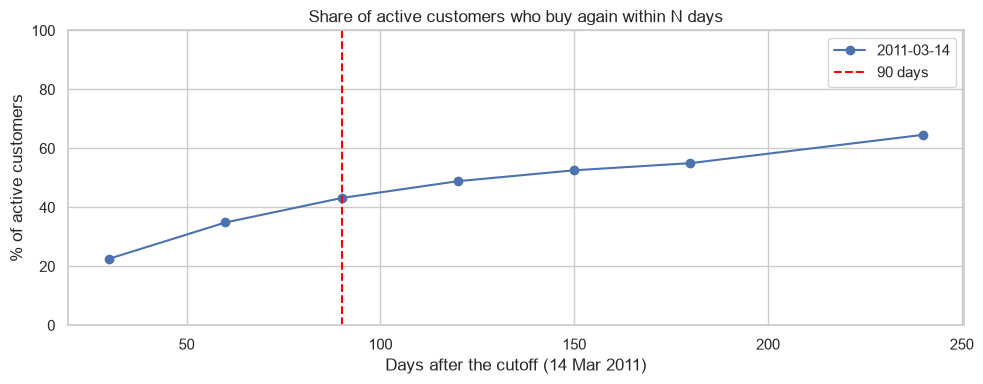

Active customers at the cutoff: 3333
30     22.6
60     34.9
90     43.2
120    48.9
150    52.6
180    55.0
240    64.6
Name: 2011-03-14, dtype: float64


In [5]:
# For three TRAINING cutoffs (the valid and test periods are not touched):
# of the customers who bought in the last 180 days, what share buys again within N days?
windows = [30, 60, 90, 120, 150, 180, 240]
curves = {}
active_count = {}

for cutoff in pd.to_datetime(["2010-09-15", "2010-12-14", "2011-03-14"]):
    # Customers with at least one purchase in the 180 days before the cutoff
    past = invoices[invoices["invoice_date"] < cutoff]
    active = past[past["invoice_date"] >= cutoff - pd.Timedelta(days=180)]["customer_id"].unique()

    # Days until their NEXT purchase after the cutoff
    future = invoices[(invoices["invoice_date"] >= cutoff) & (invoices["customer_id"].isin(active))]
    days_to_next = (future.groupby("customer_id")["invoice_date"].min() - cutoff).dt.days

    # Share of ALL active customers who came back within N days
    key = str(cutoff.date())
    curves[key] = [(days_to_next <= d).sum() / len(active) * 100 for d in windows]
    active_count[key] = len(active)

curves = pd.DataFrame(curves, index=windows)

# Chart for the cutoff of 14 Mar 2011
curves["2011-03-14"].plot(marker="o", ylim=(0, 100), title="Share of active customers who buy again within N days")
plt.axvline(90, color="red", linestyle="--", label="90 days")
plt.xlabel("Days after the cutoff (14 Mar 2011)")
plt.ylabel("% of active customers")
plt.legend()
plt.tight_layout()
plt.savefig(fig_dir / "repurchase_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print("Active customers at the cutoff:", active_count["2011-03-14"])
print(curves["2011-03-14"].round(1))

## How many orders does a typical customer make?

Share of one-time buyers: 27.7 %
count    5851.0
mean        6.2
std        12.7
min         1.0
25%         1.0
50%         3.0
75%         7.0
max       371.0
dtype: float64


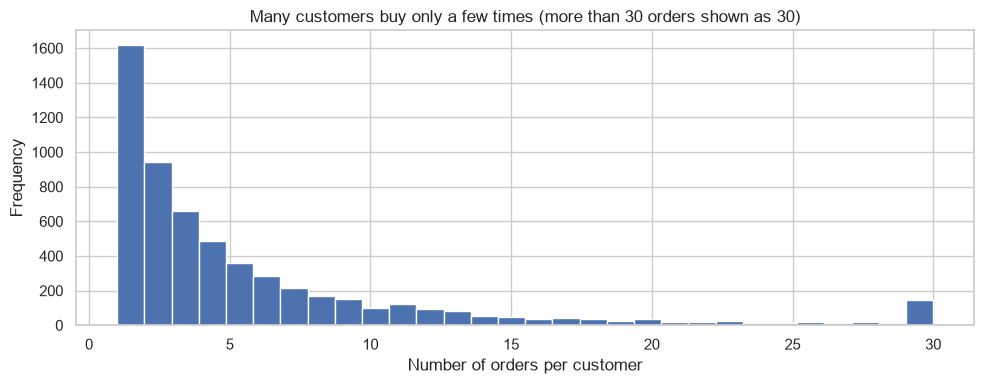

In [6]:
orders_per_customer = invoices.groupby("customer_id").size()

print("Share of one-time buyers:", round((orders_per_customer == 1).mean() * 100, 1), "%")
print(orders_per_customer.describe().round(1))

orders_per_customer.clip(upper=30).plot.hist(bins=30, title="Many customers buy only a few times (more than 30 orders shown as 30)")
plt.xlabel("Number of orders per customer")
plt.tight_layout()
plt.savefig(fig_dir / "orders_per_customer.png", dpi=150, bbox_inches="tight")
plt.show()

## Who brings the money?

Top 10% of customers bring 63% of revenue


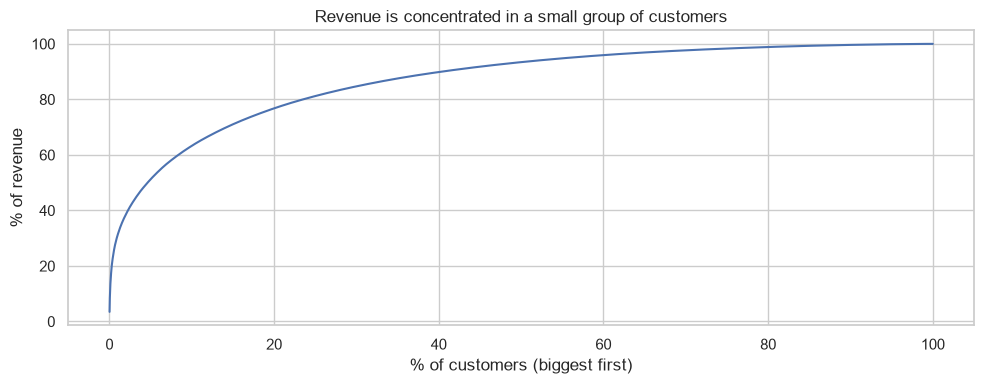

In [7]:
# Total revenue per customer, biggest first
customer_revenue = invoices.groupby("customer_id")["revenue"].sum().sort_values(ascending=False)

# Cumulative share of revenue vs share of customers
revenue_share = customer_revenue.cumsum() / customer_revenue.sum() * 100
customer_share = np.arange(1, len(revenue_share) + 1) / len(revenue_share) * 100

top10 = customer_revenue.head(int(len(customer_revenue) * 0.1)).sum() / customer_revenue.sum()
print(f"Top 10% of customers bring {top10:.0%} of revenue")

plt.plot(customer_share, revenue_share)
plt.title("Revenue is concentrated in a small group of customers")
plt.xlabel("% of customers (biggest first)")
plt.ylabel("% of revenue")
plt.tight_layout()
plt.savefig(fig_dir / "revenue_concentration.png", dpi=150, bbox_inches="tight")
plt.show()

## How big are the orders?

count    36480.0
mean       458.3
std        951.2
min          0.4
50%        302.5
90%        822.0
99%       3485.3
max      44051.6
Name: revenue, dtype: float64


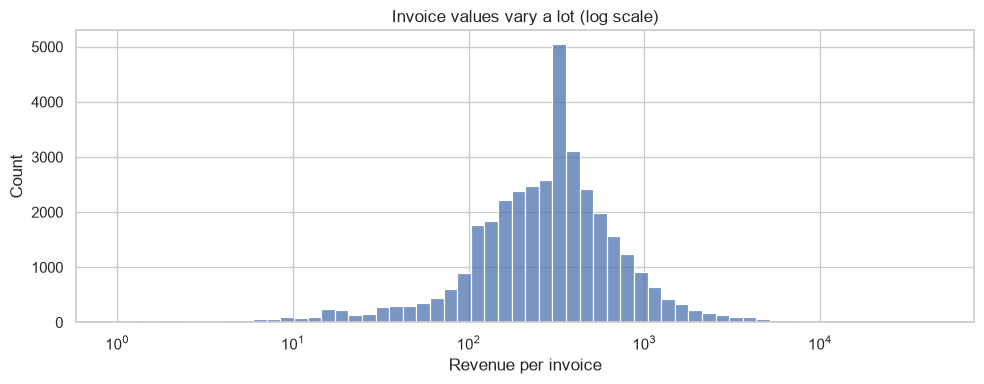

In [8]:
# Spread of invoice values
print(invoices["revenue"].describe(percentiles=[0.5, 0.9, 0.99]).round(1))

sns.histplot(invoices["revenue"].clip(lower=1), log_scale=True, bins=60)
plt.title("Invoice values vary a lot (log scale)")
plt.xlabel("Revenue per invoice")
plt.tight_layout()
plt.savefig(fig_dir / "invoice_value.png", dpi=150, bbox_inches="tight")
plt.show()

## Which countries do customers come from?

country
United Kingdom    83.4
EIRE               3.5
Netherlands        3.3
Germany            2.3
France             1.8
Australia          1.0
Spain              0.6
Switzerland        0.6
Name: line_total, dtype: float64


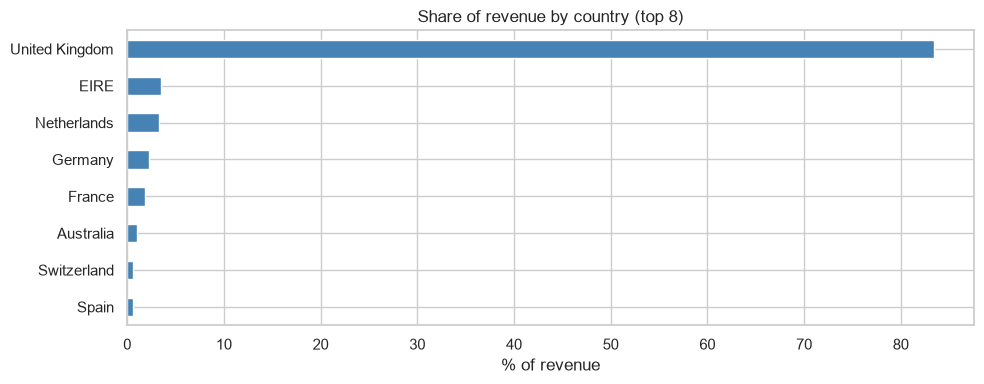

In [9]:
# Share of revenue by country
country_revenue = sales.groupby("country")["line_total"].sum().sort_values(ascending=False)
top_countries = (country_revenue / country_revenue.sum() * 100).round(1).head(8)
print(top_countries)

top_countries.sort_values().plot.barh(color="steelblue", title="Share of revenue by country (top 8)")
plt.xlabel("% of revenue")
plt.ylabel("")
plt.tight_layout()
plt.savefig(fig_dir / "country_share.png", dpi=150, bbox_inches="tight")
plt.show()

## How important are returns?

In [10]:
# Return value (quantity is negative in returns, so take the absolute value)
return_value = (returns["quantity"] * returns["price"]).abs().sum()
print("Returns value as % of sales value:", round(return_value / sales["line_total"].sum() * 100, 1))

# Customers with at least one return, among customers who have real purchases
returners = returns[returns["customer_id"].isin(invoices["customer_id"])]["customer_id"].nunique()
print("Customers with at least one return:", returners, f"({returners / invoices['customer_id'].nunique():.0%})")

Returns value as % of sales value: 2.2
Customers with at least one return: 2335 (40%)


## Are many invoices placed on the same day?

In [11]:
# Share of gaps that are exactly 0 days (a second invoice on the same day)
print("Same-day gaps:", round((gaps == 0).mean() * 100, 1), "%")

Same-day gaps: 13.1 %


## Is the biggest invoice a real purchase?

In [12]:
# The 3 biggest invoices
big = invoices.sort_values("revenue", ascending=False).head(3)
print(big[["customer_id", "invoice", "invoice_date", "revenue"]])

# Lines of the biggest invoice
top = big.iloc[0]
sales[sales["invoice"] == top["invoice"]][["invoice", "stockcode", "description", "quantity", "price", "invoicedate"]].head(10)

       customer_id invoice        invoice_date  revenue
11071        14156  493819 2010-01-07 12:34:00  44051.6
17498        15098  556444 2011-06-10 15:28:00  38970.0
31109        17450  524181 2010-09-27 16:59:00  33167.8


,invoice,stockcode,description,quantity,price,invoicedate
32277,493819,21912,VINTAGE SNAKES & LADDERS,216,3.39,2010-01-07 12:34:00
32278,493819,21749,LARGE RED SPOT WINDMILL,288,1.85,2010-01-07 12:34:00
32279,493819,21974,SET OF 36 PAISLEY FLOWER DOILIES,288,1.25,2010-01-07 12:34:00
32280,493819,21877,HOME SWEET HOME MUG,288,1.06,2010-01-07 12:34:00
32281,493819,21746,SMALL RED SPOT WINDMILL,192,1.06,2010-01-07 12:34:00
32282,493819,21843,RETRO SPOT CAKE STAND,144,10.95,2010-01-07 12:34:00
32283,493819,47502,POLKADOT CUTLERY 24 PCS IN TRAY,200,9.95,2010-01-07 12:34:00
32284,493819,84968D,S/16 VINTAGE RED CUTLERY,96,10.95,2010-01-07 12:34:00
32285,493819,84968C,S/16 VINTAGE PISTACHIO CUTLERY,96,10.95,2010-01-07 12:34:00
32286,493819,85123A,WHITE HANGING HEART T-LIGHT HOLDER,160,2.55,2010-01-07 12:34:00


In [13]:
# Cancellations of the same customer within 30 days after the biggest invoice
returns[
    (returns["customer_id"] == top["customer_id"])
    & (returns["invoicedate"] >= top["invoice_date"])
    & (returns["invoicedate"] <= top["invoice_date"] + pd.Timedelta(days=30))
][["invoice", "stockcode", "description", "quantity", "price", "invoicedate"]].head(10)

,invoice,stockcode,description,quantity,price,invoicedate
997,C493852,21257,VICTORIAN SEWING BOX MEDIUM,-1,6.60,2010-01-07 15:50:00
1189,C494973,20726,LUNCH BAG WOODLAND,-50,1.45,2010-01-20 11:06:00
1190,C494973,20715,LITTLE FLOWER SHOPPER BAG,-400,1.06,2010-01-20 11:06:00


## Are there non-product rows (postage, fees)?

In [14]:
# Rows whose stock code does not start with 5 digits (normal products do)
non_product = sales[~sales["stockcode"].str.match(r"^\d{5}")]
print("Rows with a stock code that does not start with 5 digits:", len(non_product))

non_product.groupby(["stockcode", "description"]).agg(rows=("invoice", "size"), revenue=("line_total", "sum"))

Rows with a stock code that does not start with 5 digits: 19


,,rows,revenue
stockcode,description,,
PADS,PADS TO MATCH ALL CUSHIONS,17,0.017
SP1002,KID'S CHALKBOARD/EASEL,2,14.750


## Is the 90-day curve stable across cutoffs?

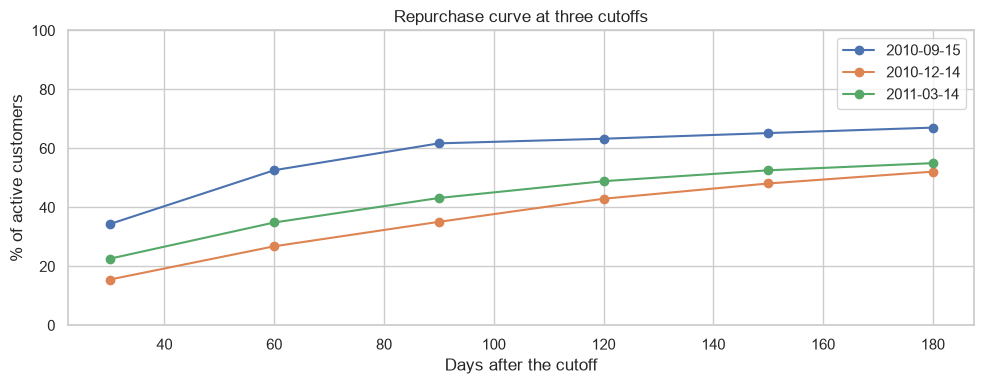

     2010-09-15  2010-12-14  2011-03-14
30         34.3        15.5        22.6
60         52.6        26.8        34.9
90         61.7        35.1        43.2
120        63.3        42.9        48.9
150        65.2        48.1        52.6
180        67.0        52.1        55.0


In [15]:
# The three curves, shown up to 180 days
curves_180 = curves.loc[:180]

curves_180.plot(marker="o", ylim=(0, 100), title="Repurchase curve at three cutoffs")
plt.xlabel("Days after the cutoff")
plt.ylabel("% of active customers")
plt.tight_layout()
plt.savefig(fig_dir / "repurchase_curve_cutoffs.png", dpi=150, bbox_inches="tight")
plt.show()

print(curves_180.round(1))